In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATA_DIR)

for file in DATA_DIR.iterdir():
    print(file.name)

Project root: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage
Dataset directory: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage\data\raw
GUIDE_Test.csv
GUIDE_Train.csv


In [13]:
train_path = DATA_DIR / "GUIDE_Train.csv"

sample = pd.read_csv(
    train_path,
    nrows=10_000,
    low_memory=False
)

sample.head()

,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,180388628218,0,612,123247,2024-06-04T06:05:15.000Z,7,6,InitialAccess,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,31,6,3
1,455266534868,88,326,210035,2024-06-14T03:01:25.000Z,58,43,Exfiltration,NaN,FalsePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
2,1056561957389,809,58352,712507,2024-06-13T04:52:55.000Z,423,298,InitialAccess,T1189,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
3,1279900258736,92,32992,774301,2024-06-10T16:39:36.000Z,2,2,CommandAndControl,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
4,214748368522,148,4359,188041,2024-06-15T01:08:07.000Z,9,74,Execution,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


In [14]:
print(sample.shape)

(10000, 45)


In [15]:
sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Id                  10000 non-null  int64  
 1   OrgId               10000 non-null  int64  
 2   IncidentId          10000 non-null  int64  
 3   AlertId             10000 non-null  int64  
 4   Timestamp           10000 non-null  object 
 5   DetectorId          10000 non-null  int64  
 6   AlertTitle          10000 non-null  int64  
 7   Category            10000 non-null  object 
 8   MitreTechniques     4201 non-null   object 
 9   IncidentGrade       9947 non-null   object 
 10  ActionGrouped       59 non-null     object 
 11  ActionGranular      59 non-null     object 
 12  EntityType          10000 non-null  object 
 13  EvidenceRole        10000 non-null  object 
 14  DeviceId            10000 non-null  int64  
 15  Sha256              10000 non-null  int64  
 16  IpAdd

In [16]:
sample.head().T

,0,1,2,3,4
Id,180388628218,455266534868,1056561957389,1279900258736,214748368522
OrgId,0,88,809,92,148
IncidentId,612,326,58352,32992,4359
AlertId,123247,210035,712507,774301,188041
Timestamp,2024-06-04T06:05:15.000Z,2024-06-14T03:01:25.000Z,2024-06-13T04:52:55.000Z,2024-06-10T16:39:36.000Z,2024-06-15T01:08:07.000Z
DetectorId,7,58,423,2,9
AlertTitle,6,43,298,2,74
Category,InitialAccess,Exfiltration,InitialAccess,CommandAndControl,Execution
MitreTechniques,NaN,NaN,T1189,NaN,NaN
IncidentGrade,TruePositive,FalsePositive,FalsePositive,BenignPositive,TruePositive


In [17]:
sample.head()

,Id,OrgId,IncidentId,AlertId,Timestamp,DetectorId,AlertTitle,Category,MitreTechniques,IncidentGrade,...,ResourceType,Roles,OSFamily,OSVersion,AntispamDirection,SuspicionLevel,LastVerdict,CountryCode,State,City
0,180388628218,0,612,123247,2024-06-04T06:05:15.000Z,7,6,InitialAccess,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,31,6,3
1,455266534868,88,326,210035,2024-06-14T03:01:25.000Z,58,43,Exfiltration,NaN,FalsePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630
2,1056561957389,809,58352,712507,2024-06-13T04:52:55.000Z,423,298,InitialAccess,T1189,FalsePositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
3,1279900258736,92,32992,774301,2024-06-10T16:39:36.000Z,2,2,CommandAndControl,NaN,BenignPositive,...,NaN,NaN,5,66,NaN,Suspicious,Suspicious,242,1445,10630
4,214748368522,148,4359,188041,2024-06-15T01:08:07.000Z,9,74,Execution,NaN,TruePositive,...,NaN,NaN,5,66,NaN,NaN,NaN,242,1445,10630


## Target analysis

In [18]:
TARGET = "IncidentGrade"

print("Target exists:", TARGET in sample.columns)

print("\nClass counts:")
print(sample[TARGET].value_counts(dropna=False))

print("\nClass percentages:")
print(
    sample[TARGET]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Target exists: True

Class counts:
IncidentGrade
BenignPositive    4391
TruePositive      3446
FalsePositive     2110
NaN                 53
Name: count, dtype: int64

Class percentages:
IncidentGrade
BenignPositive    43.91
TruePositive      34.46
FalsePositive     21.10
NaN                0.53
Name: proportion, dtype: float64


## Target graph

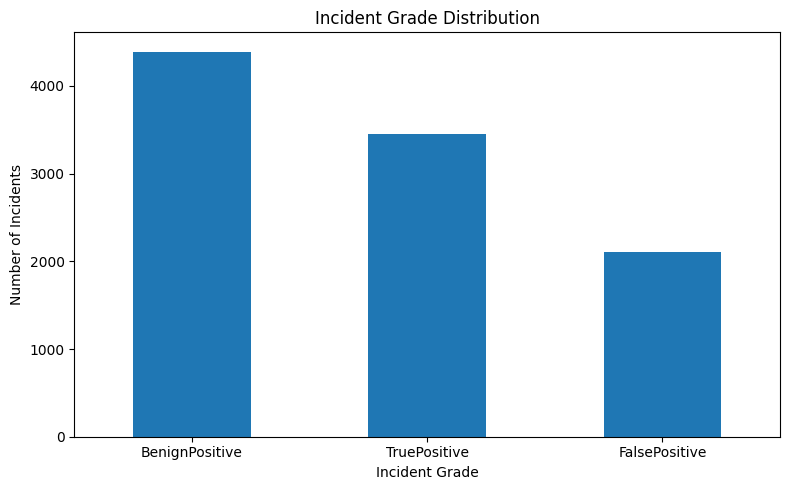

In [19]:
target_counts = sample[TARGET].value_counts()

plt.figure(figsize=(8, 5))
target_counts.plot(kind="bar")

plt.title("Incident Grade Distribution")
plt.xlabel("Incident Grade")
plt.ylabel("Number of Incidents")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Missing values

In [20]:
missing = sample.isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(sample) * 100).round(2)
})

missing_df = (
    missing_df[missing_df["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

missing_df

,missing_count,missing_percent
ResourceType,9992,99.92
ActionGranular,9941,99.41
ActionGrouped,9941,99.41
ThreatFamily,9923,99.23
EmailClusterId,9881,98.81
AntispamDirection,9823,98.23
Roles,9789,97.89
SuspicionLevel,8462,84.62
LastVerdict,7600,76.00
MitreTechniques,5799,57.99


## Visualize missingness

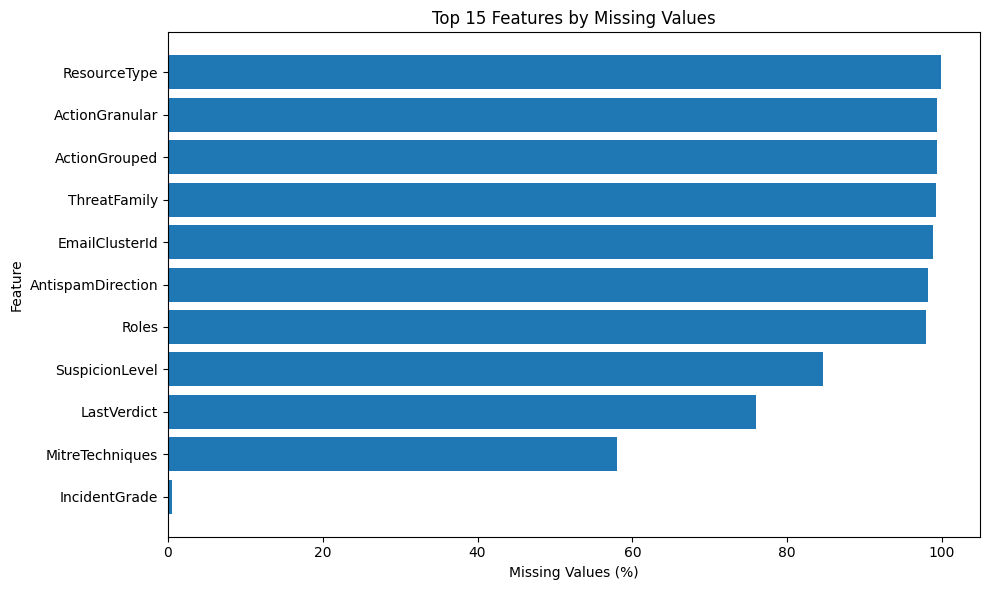

In [21]:
missing_plot = missing_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    missing_plot.index,
    missing_plot["missing_percent"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Top 15 Features by Missing Values")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Data types

In [23]:
numeric_columns = sample.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = sample.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric dtype columns:", len(numeric_columns))
print(numeric_columns)

print("\nObject/categorical dtype columns:", len(categorical_columns))
print(categorical_columns)

Numeric dtype columns: 31
['Id', 'OrgId', 'IncidentId', 'AlertId', 'DetectorId', 'AlertTitle', 'DeviceId', 'Sha256', 'IpAddress', 'Url', 'AccountSid', 'AccountUpn', 'AccountObjectId', 'AccountName', 'DeviceName', 'NetworkMessageId', 'EmailClusterId', 'RegistryKey', 'RegistryValueName', 'RegistryValueData', 'ApplicationId', 'ApplicationName', 'OAuthApplicationId', 'FileName', 'FolderPath', 'ResourceIdName', 'OSFamily', 'OSVersion', 'CountryCode', 'State', 'City']

Object/categorical dtype columns: 14
['Timestamp', 'Category', 'MitreTechniques', 'IncidentGrade', 'ActionGrouped', 'ActionGranular', 'EntityType', 'EvidenceRole', 'ThreatFamily', 'ResourceType', 'Roles', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict']


## Unique values / cardinality

In [24]:
unique_counts = (
    sample
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

unique_counts

AlertId               9613
Timestamp             9580
Id                    7203
IncidentId            7148
AccountUpn            3386
AccountName           2323
AccountSid            2211
AlertTitle            2205
AccountObjectId       2200
IpAddress             1879
NetworkMessageId      1193
OrgId                 1130
DetectorId             807
FileName               706
DeviceName             686
Url                    603
Sha256                 512
FolderPath             465
DeviceId               375
City                   196
MitreTechniques        183
State                  136
EmailClusterId         115
CountryCode             68
ThreatFamily            60
ApplicationName         23
ApplicationId           21
EntityType              20
Category                17
ResourceIdName          12
RegistryKey             10
ActionGranular          10
Roles                    7
OSVersion                6
ResourceType             6
RegistryValueName        5
IncidentGrade            4
L

In [25]:
cardinality = pd.DataFrame({
    "unique_values": sample.nunique(dropna=False)
})

cardinality["unique_ratio"] = (
    cardinality["unique_values"] / len(sample)
).round(4)

cardinality.sort_values(
    "unique_ratio",
    ascending=False
).head(20)

,unique_values,unique_ratio
AlertId,9613,0.9613
Timestamp,9580,0.9580
Id,7203,0.7203
IncidentId,7148,0.7148
AccountUpn,3386,0.3386
AccountName,2323,0.2323
AccountSid,2211,0.2211
AlertTitle,2205,0.2205
AccountObjectId,2200,0.2200
IpAddress,1879,0.1879


## Automatically find ID-like columns

In [31]:
import re

possible_id_columns = [
    column
    for column in sample.columns
    if re.search(r"(^Id$|Id$|Sid$|IdName$)", column)
]

possible_id_columns

['Id',
 'OrgId',
 'IncidentId',
 'AlertId',
 'DetectorId',
 'DeviceId',
 'AccountSid',
 'AccountObjectId',
 'NetworkMessageId',
 'EmailClusterId',
 'ApplicationId',
 'OAuthApplicationId',
 'ResourceIdName']

## Constant columns

In [27]:
constant_columns = [
    column
    for column in sample.columns
    if sample[column].nunique(dropna=False) <= 1
]

print("Constant columns:")
print(constant_columns)

Constant columns:
[]


## Duplicate rows

In [28]:
duplicate_rows = sample.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


## Timestamp

In [29]:
sample["Timestamp"] = pd.to_datetime(
    sample["Timestamp"],
    errors="coerce",
    utc=True
)

print(sample["Timestamp"].dtype)

sample["Timestamp"].head()

datetime64[ns, UTC]


0   2024-06-04 06:05:15+00:00
1   2024-06-14 03:01:25+00:00
2   2024-06-13 04:52:55+00:00
3   2024-06-10 16:39:36+00:00
4   2024-06-15 01:08:07+00:00
Name: Timestamp, dtype: datetime64[ns, UTC]

## First Summary Table

In [30]:
feature_summary = pd.DataFrame({
    "dtype": sample.dtypes.astype(str),
    "missing_pct": (
        sample.isna().mean() * 100
    ).round(2),
    "unique_values": sample.nunique(dropna=False),
})

feature_summary["unique_ratio"] = (
    feature_summary["unique_values"] / len(sample)
).round(4)

feature_summary

,dtype,missing_pct,unique_values,unique_ratio
Id,int64,0.00,7203,0.7203
OrgId,int64,0.00,1130,0.1130
IncidentId,int64,0.00,7148,0.7148
AlertId,int64,0.00,9613,0.9613
Timestamp,"datetime64[ns, UTC]",0.00,9580,0.9580
DetectorId,int64,0.00,807,0.0807
AlertTitle,int64,0.00,2205,0.2205
Category,object,0.00,17,0.0017
MitreTechniques,object,57.99,183,0.0183
IncidentGrade,object,0.53,4,0.0004


## Group structure

In [32]:
sample["IncidentGroup"] = (
    sample["OrgId"].astype(str)
    + "_"
    + sample["IncidentId"].astype(str)
)

print("Rows:", len(sample))
print("Unique incidents:", sample["IncidentGroup"].nunique())

rows_per_incident = (
    sample.groupby("IncidentGroup")
    .size()
)

print("\nRows per incident:")
print(rows_per_incident.describe())

print("\nIncidents with more than one row:")
print((rows_per_incident > 1).sum())

Rows: 10000
Unique incidents: 7203

Rows per incident:
count    7203.00000
mean        1.38831
std         1.71063
min         1.00000
25%         1.00000
50%         1.00000
75%         1.00000
max        38.00000
dtype: float64

Incidents with more than one row:
764


## LastVerdict vs Target

In [33]:
pd.crosstab(
    sample["LastVerdict"].fillna("Missing"),
    sample[TARGET],
    normalize="index"
).round(3)

IncidentGrade,BenignPositive,FalsePositive,TruePositive
LastVerdict,,,
Malicious,0.602,0.118,0.280
Missing,0.390,0.232,0.377
NoThreatsFound,0.520,0.179,0.301
Suspicious,0.626,0.150,0.223


## SuspicionLevel vs Target

In [34]:
pd.crosstab(
    sample["SuspicionLevel"].fillna("Missing"),
    sample[TARGET],
    normalize="index"
).round(3)

IncidentGrade,BenignPositive,FalsePositive,TruePositive
SuspicionLevel,,,
Incriminated,1.000,0.000,0.000
Missing,0.407,0.223,0.370
Suspicious,0.633,0.152,0.215


In [35]:
for column in ["LastVerdict", "SuspicionLevel"]:
    print(f"\n=== {column} ===")

    counts = sample[column].fillna("Missing").value_counts()
    percentages = (
        sample[column]
        .fillna("Missing")
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    summary = pd.DataFrame({
        "count": counts,
        "percent": percentages
    })

    print(summary)


=== LastVerdict ===
                count  percent
LastVerdict                   
Missing          7600    76.00
Suspicious       1497    14.97
Malicious         477     4.77
NoThreatsFound    426     4.26

=== SuspicionLevel ===
                count  percent
SuspicionLevel                
Missing          8462    84.62
Suspicious       1536    15.36
Incriminated        2     0.02


In [36]:
incident_label_counts = (
    sample
    .dropna(subset=[TARGET])
    .groupby("IncidentGroup")[TARGET]
    .nunique()
)

print(
    "Incidents with more than one target label:",
    (incident_label_counts > 1).sum()
)

incident_label_counts.describe()

Incidents with more than one target label: 0


count    7151.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: IncidentGrade, dtype: float64

## Timestamp feature engineering

In [38]:
sample["Hour"] = sample["Timestamp"].dt.hour
sample["DayOfWeek"] = sample["Timestamp"].dt.dayofweek
sample["IsWeekend"] = (
    sample["DayOfWeek"] >= 5
).astype(int)

sample[[
    "Timestamp",
    "Hour",
    "DayOfWeek",
    "IsWeekend"
]].head()

,Timestamp,Hour,DayOfWeek,IsWeekend
0,2024-06-04 06:05:15+00:00,6,1,0
1,2024-06-14 03:01:25+00:00,3,4,0
2,2024-06-13 04:52:55+00:00,4,3,0
3,2024-06-10 16:39:36+00:00,16,0,0
4,2024-06-15 01:08:07+00:00,1,5,1
